**spider plot**

In [16]:
import pandas as pd

# Compute correlation with target
corr = df.corr(numeric_only=True)['half-cell_potential_v']

# Remove self-correlation
corr = corr.drop('half-cell_potential_v')

print(corr)

temperature_c         -0.599430
humidity_%            -0.400347
surface_resistivity    0.681702
surface_roughness     -0.156344
Name: half-cell_potential_v, dtype: float64


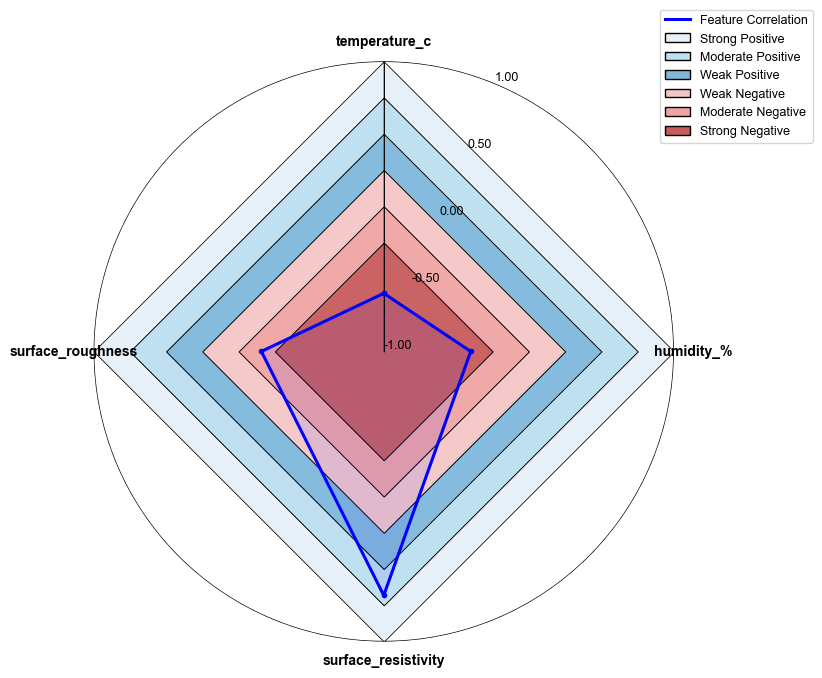

In [105]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib as mpl
import pandas as pd

df = pd.read_csv('data.csv')
df.dropna(inplace=True)
# Compute correlation with target
corr = df.corr(numeric_only=True)['half-cell_potential_v']

# Remove self-correlation
corr = corr.drop('half-cell_potential_v')

# -------------------------------
# Typography (STRICT Helvetica)
# -------------------------------
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Helvetica']
mpl.rcParams['axes.unicode_minus'] = False

mpl.rcParams['font.size'] = 11
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.titleweight'] = 'bold'

# -------------------------------
# Data
# -------------------------------
labels = corr.index.tolist()
values = corr.values

N = len(labels)

angles = np.linspace(0, 2*np.pi, N, endpoint=False)
angles = np.concatenate([angles, [angles[0]]])
values = np.concatenate([values, [values[0]]])

# -------------------------------
# Figure setup (journal layout)
# -------------------------------
fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw=dict(polar=True))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Start from top, clockwise (important for Q1 radar style)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# -------------------------------
# Band structure (clean segmented look)
# -------------------------------
bands = [
    (0.75, 1.0, '#e8f1f8'),
    (0.50, 0.75, '#bcdff1'),
    (0.25, 0.50, '#7fb8da'),
    (0.00, 0.25, '#f5c6c6'),
    (-0.25, 0.00, '#f0a3a3'),
    (-1.00, -0.25, '#c85c5c')
]

for low, high, color in bands:
    ax.fill_between(angles, low, high, color=color, alpha=0.95, edgecolor='black', linewidth=0.6)

# -------------------------------
# Correlation line (high contrast)
# -------------------------------
ax.plot(
    angles,
    values,
    color='blue',
    linewidth=2.2,
    marker='o',
    markersize=3
)

ax.fill(angles, values, color='blue', alpha=0.08)

# -------------------------------
# Axis labels (clean journal spacing)
# -------------------------------
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')

ax.set_ylim(-1, 1)

# Radial ticks (match reference style)
ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.set_yticklabels(['-1.00', '-0.50', '0.00', '0.50', '1.00'], fontsize=9)

# -------------------------------
# Remove clutter (VERY IMPORTANT for Q1)
# -------------------------------
ax.grid(False)
ax.spines['polar'].set_visible(False)

# -------------------------------
# Add clean outer boundary circle
# -------------------------------
theta = np.linspace(0, 2*np.pi, 500)
ax.plot(theta, np.ones_like(theta), color='black', linewidth=1.0)

# -------------------------------
# Legend (compact, clean box)
# -------------------------------
legend_elements = [
    Patch(facecolor='#e8f1f8', edgecolor='black', label='Strong Positive'),
    Patch(facecolor='#bcdff1', edgecolor='black', label='Moderate Positive'),
    Patch(facecolor='#7fb8da', edgecolor='black', label='Weak Positive'),
    Patch(facecolor='#f5c6c6', edgecolor='black', label='Weak Negative'),
    Patch(facecolor='#f0a3a3', edgecolor='black', label='Moderate Negative'),
    Patch(facecolor='#c85c5c', edgecolor='black', label='Strong Negative'),
]

legend_elements.insert(
    0,
    plt.Line2D([0], [0], color='blue', lw=2.2, label='Feature Correlation')
)

ax.legend(
    handles=legend_elements,
    loc='upper right',
    bbox_to_anchor=(1.25, 1.1),
    frameon=True,
    fontsize=9
)

# -------------------------------
# Title (optional Q1 style minimal)
# -------------------------------

plt.tight_layout()
plt.savefig("spider_plot.pdf", dpi=1000, bbox_inches="tight")
plt.show()

**PCA plot main**

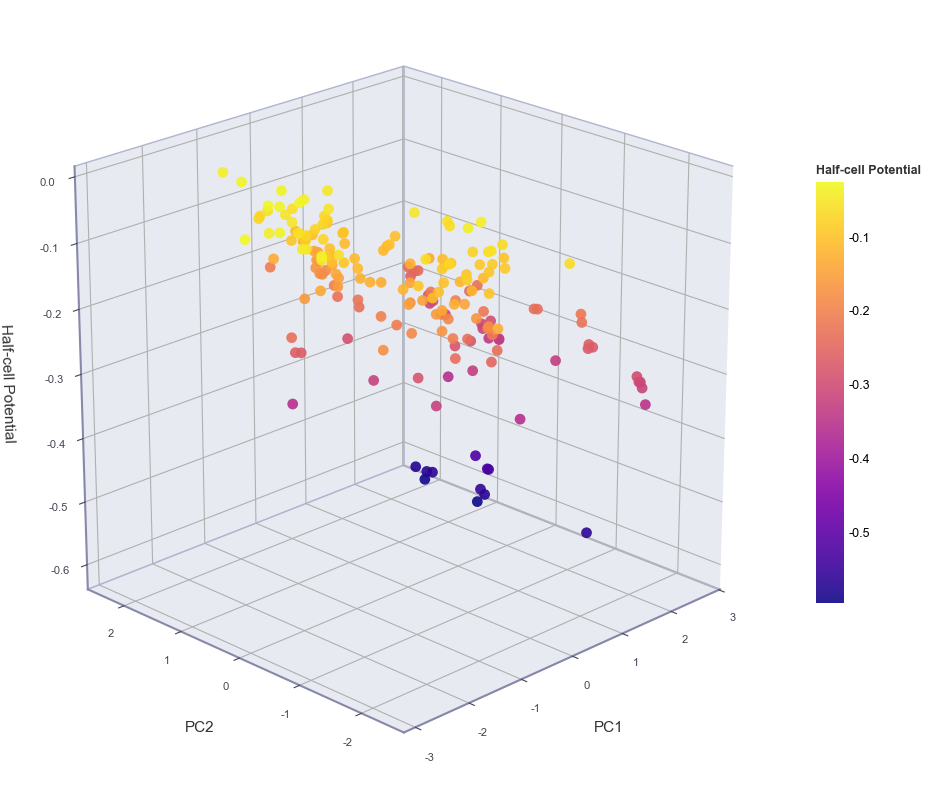

In [104]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# -----------------------------
# 1. Load dataset
# -----------------------------
df = pd.read_csv('data.csv')
df.dropna(inplace=True)

X = df.drop(columns=["half-cell_potential_v"])
y = df['half-cell_potential_v']

scaler = StandardScaler()

x_scaled = scaler.fit_transform(X)

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    x_scaled, y, test_size=0.2, random_state=42
)

pca = PCA(n_components=2)

pca_val = pca.fit_transform(X_train)

# ── Plot ───────────────────────────────────────────────────────────────────────

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor("white")

ax = fig.add_subplot(111, projection="3d")
ax.set_facecolor("white")

ax.set_box_aspect([1.4, 1.4, 1.4])
ax.view_init(elev=22, azim=225)
ax.dist = 8

# ── Pane background ────────────────────────────────────────────────────────────
for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
    pane.fill = True
    pane.set_facecolor("#E8EAF2")
    pane.set_alpha(1.0)
    pane.set_edgecolor("#B0B4CC")   # darker edge = visible cube walls

# White grid lines
ax.grid(True, linestyle="-", linewidth=0.7, color="white")

# ── Make tick lines visible (gives 3D depth to axes) ──────────────────────────
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis._axinfo["tick"]["inward_factor"]  = 0.2
    axis._axinfo["tick"]["outward_factor"] = 0.0
    axis._axinfo["axisline"]["linewidth"]  = 1.5
    axis._axinfo["axisline"]["color"]      = (0.5, 0.5, 0.6, 1.0)

# ── Spine / axis line color ────────────────────────────────────────────────────
ax.xaxis.line.set_color("#8888AA")
ax.yaxis.line.set_color("#8888AA")
ax.zaxis.line.set_color("#8888AA")
ax.xaxis.line.set_linewidth(1.5)
ax.yaxis.line.set_linewidth(1.5)
ax.zaxis.line.set_linewidth(1.5)

# ── Tick label color ───────────────────────────────────────────────────────────
ax.tick_params(labelsize=8, colors="#444455", pad=4, width=0)

# ── Scatter ────────────────────────────────────────────────────────────────────
sc = ax.scatter(
    pca_val[:, 0],
    pca_val[:, 1],
    y_train,
    c=y_train,
    cmap="plasma",
    s=60,
    alpha=0.90,
    depthshade=True,
    edgecolors="none",
)

# ── Axis labels ────────────────────────────────────────────────────────────────
ax.set_xlabel("PC1", fontsize=11, labelpad=14, color="#333333")
ax.set_ylabel("PC2", fontsize=11, labelpad=14, color="#333333")
ax.set_zlabel("Half-cell Potential", fontsize=11, labelpad=12, color="#333333")

# ── Colorbar with label on top ─────────────────────────────────────────────────
cbar = fig.colorbar(sc, ax=ax, pad=0.04, shrink=0.55, aspect=15)
cbar.set_label("")
cbar.ax.set_title("Half-cell Potential", fontsize=9,
                  color="#333333", pad=6, loc="left")
cbar.ax.tick_params(labelsize=9, length=0)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.savefig("pca_3d_plot.pdf", dpi=1000, bbox_inches="tight")
plt.show()